In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

CLEAN_PATH = "../data/processed/loans_clean.csv"
FIG_DIR = "../docs/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# parse_dates turns the saved text back into real dates
df = pd.read_csv(CLEAN_PATH, parse_dates=["IssueDate"])
print(df.shape)                                            # expect (1347681, 11) if every Day 2 cell ran

overall_default_rate = df["Default"].mean()
plot_sample = df.sample(100_000, random_state=42)          # for plots that would be too slow on 1.35 million points


def save_fig(name):
    """Tidy the layout, save the chart for the report and presentation, then show it."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

(1347681, 11)


In [2]:
print("Loans:", f"{len(df):,}")
print("Default rate:", round(overall_default_rate, 3))
print("Issue years:", df["IssueYear"].min(), "to", df["IssueYear"].max())
print("Median income:", round(df["Income"].median()), "| median loan:", round(df["LoanAmount"].median()))
print("Median credit score:", df["CreditScore"].median(), "| median DTI:", round(df["DTI"].median(), 1))
print("Distinct purposes:", df["Purpose"].nunique(), "| states:", df["State"].nunique())

Loans: 1,347,681
Default rate: 0.2
Issue years: 2007 to 2018
Median income: 65000 | median loan: 12000
Median credit score: 692.0 | median DTI: 17.6
Distinct purposes: 14 | states: 51


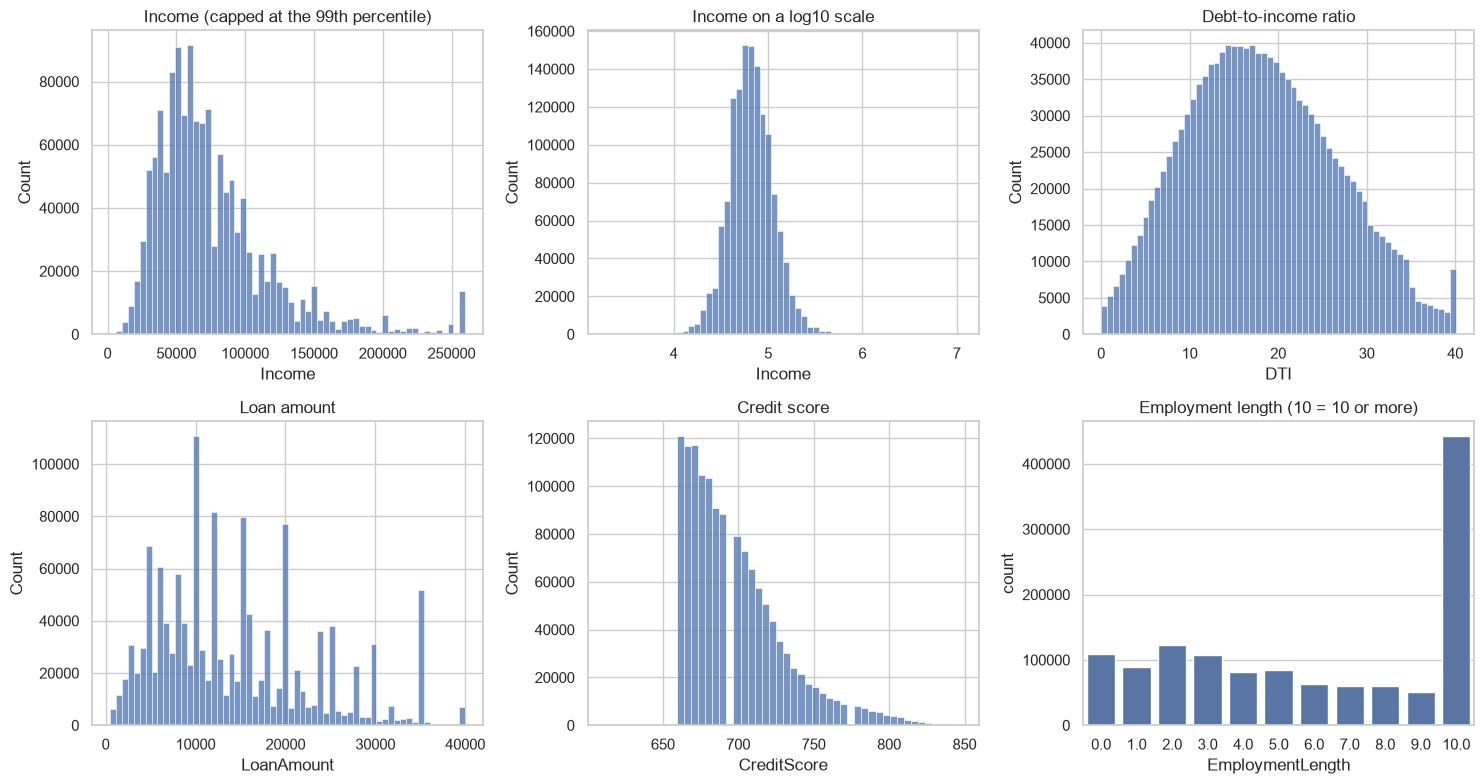

Skewness:
Income              45.40
DTI                 27.11
LoanAmount           0.78
CreditScore          1.28
EmploymentLength    -0.22
dtype: float64

Percentiles (note how far the maximum is from the 99th percentile):
           Income  LoanAmount    DTI
0.500     65000.0     12000.0   17.6
0.900    129000.0     28000.0   29.8
0.990    260000.0     35000.0   38.5
0.999    585000.0     40000.0   66.0
1.000  10999200.0     40000.0  999.0


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

income_cap = df["Income"].quantile(0.99)
sns.histplot(df["Income"].clip(upper=income_cap), bins=60, ax=axes[0, 0])
axes[0, 0].set_title("Income (capped at the 99th percentile)")
sns.histplot(np.log10(df["Income"].dropna()), bins=60, ax=axes[0, 1])
axes[0, 1].set_title("Income on a log10 scale")
sns.histplot(df["DTI"].clip(upper=df["DTI"].quantile(0.995)), bins=60, ax=axes[0, 2])
axes[0, 2].set_title("Debt-to-income ratio")
sns.histplot(df["LoanAmount"], bins=60, ax=axes[1, 0])
axes[1, 0].set_title("Loan amount")
sns.histplot(df["CreditScore"], bins=50, ax=axes[1, 1])
axes[1, 1].set_title("Credit score")
sns.countplot(x=df["EmploymentLength"], ax=axes[1, 2])
axes[1, 2].set_title("Employment length (10 = 10 or more)")
save_fig("01_numeric_distributions")

numeric_columns = ["Income", "DTI", "LoanAmount", "CreditScore", "EmploymentLength"]
print("Skewness:")
print(df[numeric_columns].skew().round(2))
print("\nPercentiles (note how far the maximum is from the 99th percentile):")
print(df[["Income", "LoanAmount", "DTI"]].quantile([0.5, 0.9, 0.99, 0.999, 1.0]).round(1))

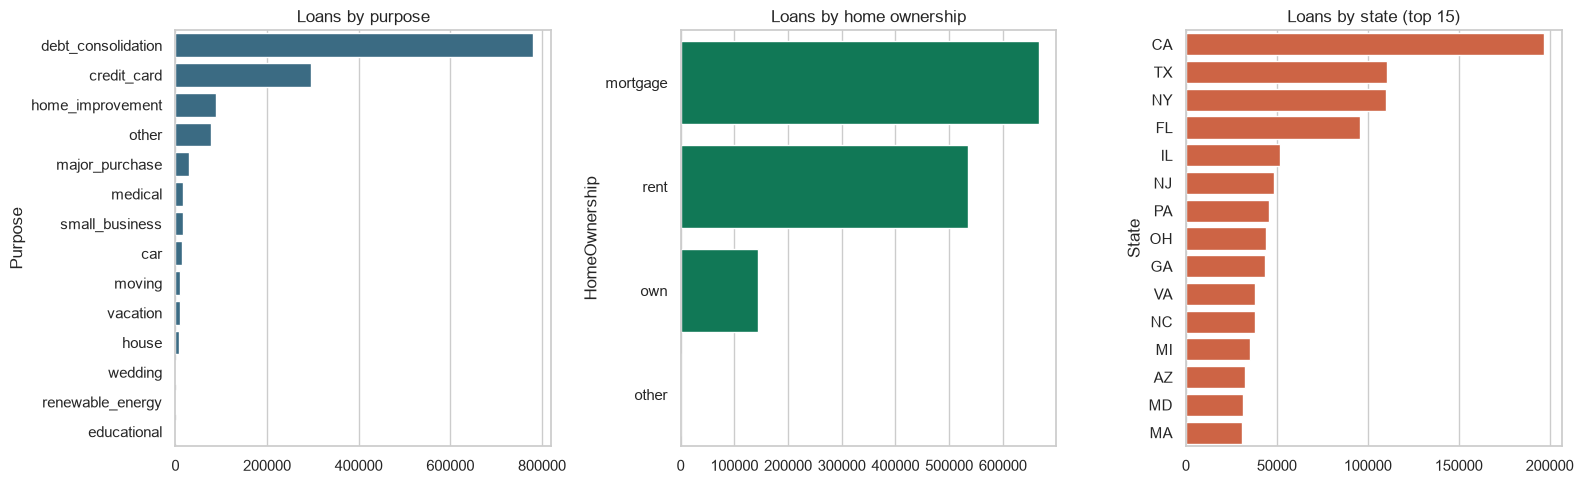

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

purpose_counts = df["Purpose"].value_counts()
sns.barplot(x=purpose_counts.values, y=purpose_counts.index, ax=axes[0], color="#2F6F8F")
axes[0].set_title("Loans by purpose")

home_counts = df["HomeOwnership"].value_counts()
sns.barplot(x=home_counts.values, y=home_counts.index, ax=axes[1], color="#00895C")
axes[1].set_title("Loans by home ownership")

state_counts = df["State"].value_counts().head(15)
sns.barplot(x=state_counts.values, y=state_counts.index, ax=axes[2], color="#E4572E")
axes[2].set_title("Loans by state (top 15)")
save_fig("02_category_counts")


In [5]:
missing = (df[numeric_columns].isna().mean() * 100).round(2).sort_values(ascending=False)
print("Missing values (%):")
print(missing)

Missing values (%):
EmploymentLength    5.8
Income              0.0
DTI                 0.0
LoanAmount          0.0
CreditScore         0.0
dtype: float64


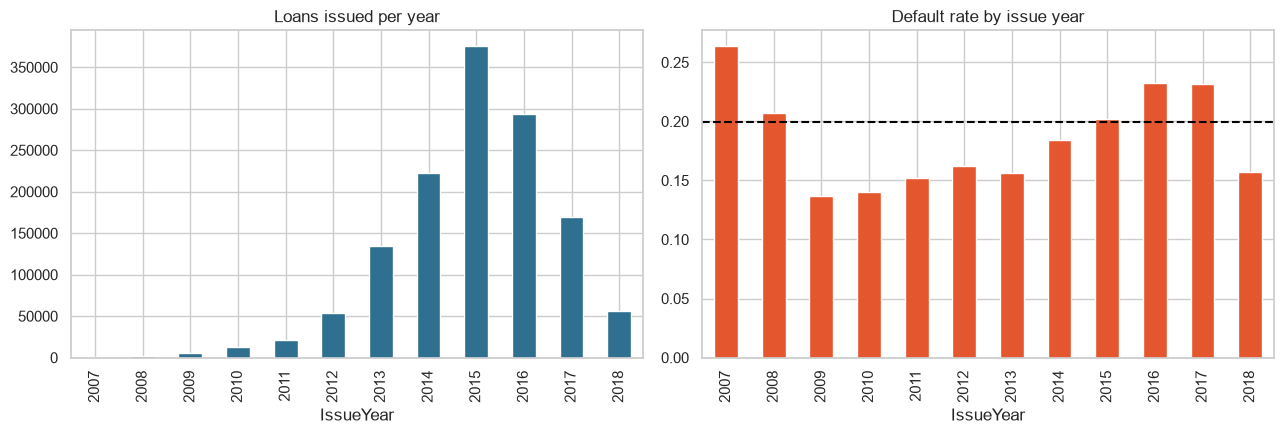

,loans,default_rate
IssueYear,,
2007,599,0.264
2008,2393,0.207
2009,5281,0.137
2010,12537,0.140
2011,21721,0.152
2012,53367,0.162
2013,134804,0.156
2014,223102,0.184
2015,375543,0.202


In [6]:
by_year = df.groupby("IssueYear")["Default"].agg(loans="size", default_rate="mean")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
by_year["loans"].plot(kind="bar", ax=axes[0], color="#2F6F8F")
axes[0].set_title("Loans issued per year")
by_year["default_rate"].plot(kind="bar", ax=axes[1], color="#E4572E")
axes[1].axhline(overall_default_rate, color="black", linestyle="--")
axes[1].set_title("Default rate by issue year")
save_fig("03_vintage")

by_year.round(3)

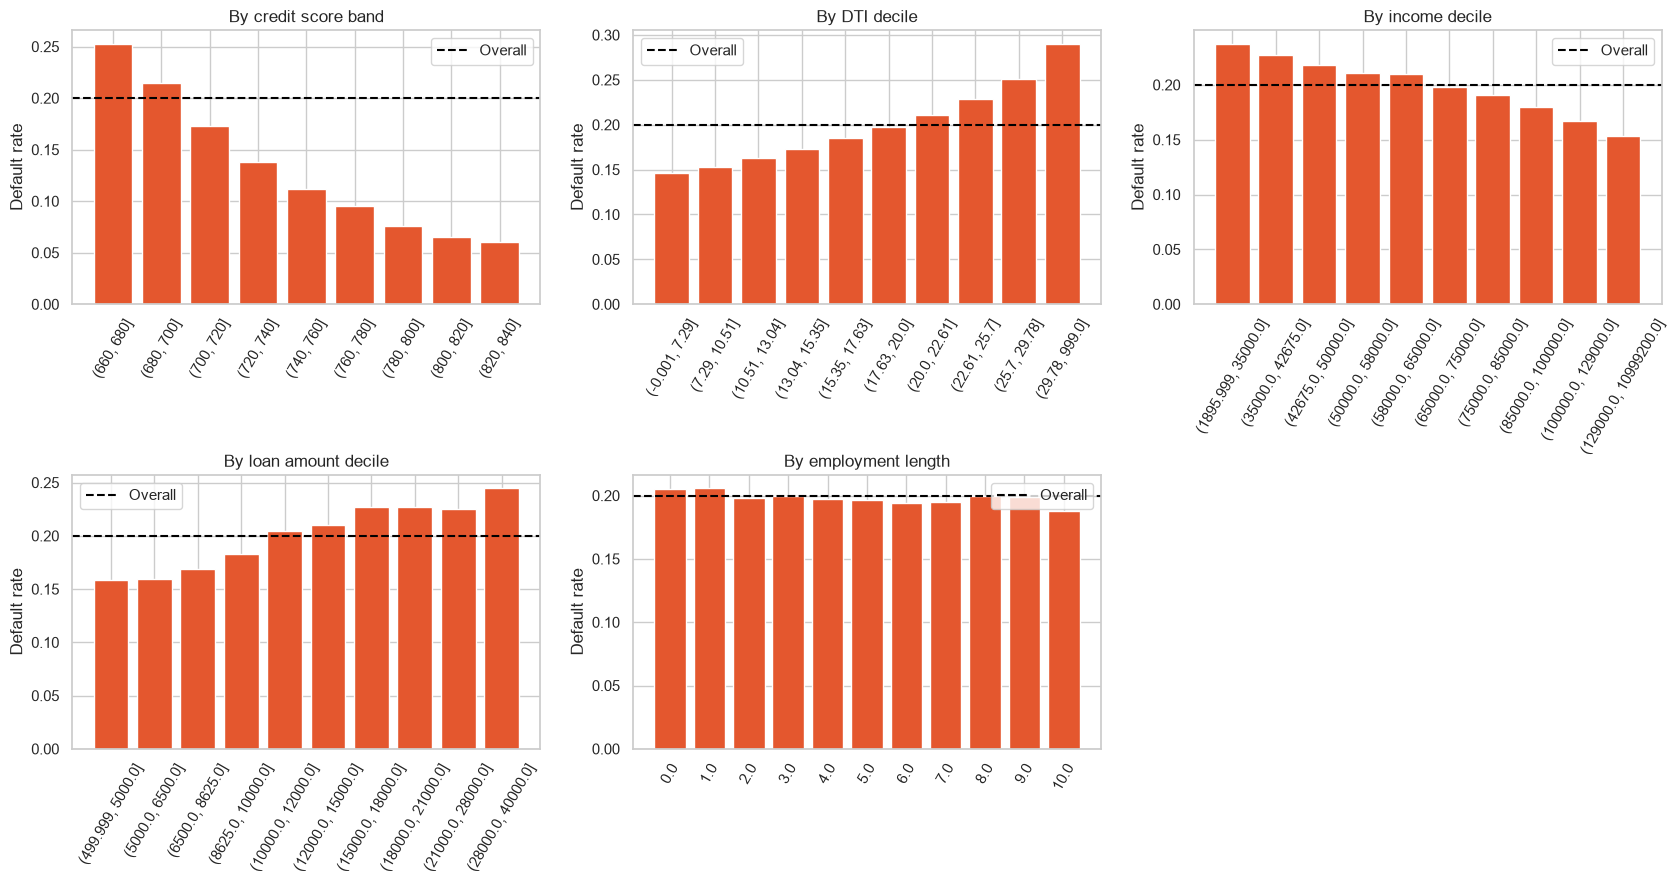

,loans,default_rate
CreditScore,,
"(660, 680]",460116,0.253
"(680, 700]",361910,0.214
"(700, 720]",246591,0.173
"(720, 740]",133283,0.138
"(740, 760]",68308,0.111
"(760, 780]",38675,0.095
"(780, 800]",22864,0.076
"(800, 820]",11443,0.065
"(820, 840]",3563,0.060


In [7]:
def default_rate_by_band(bands, min_loans=1000):
    """Number of loans and default rate for each band. Bands with few loans are hidden."""
    table = df.groupby(bands, observed=True)["Default"].agg(loans="size", default_rate="mean")
    return table[table["loans"] >= min_loans]


def plot_default_rate(table, title, ax):
    ax.bar(table.index.astype(str), table["default_rate"], color="#E4572E")
    ax.axhline(overall_default_rate, color="black", linestyle="--", label="Overall")
    ax.set_title(title)
    ax.set_ylabel("Default rate")
    ax.tick_params(axis="x", rotation=60)
    ax.legend()


score_table = default_rate_by_band(pd.cut(df["CreditScore"], np.arange(600, 880, 20)))
dti_table = default_rate_by_band(pd.qcut(df["DTI"], 10, duplicates="drop"))
income_table = default_rate_by_band(pd.qcut(df["Income"], 10, duplicates="drop"))
amount_table = default_rate_by_band(pd.qcut(df["LoanAmount"], 10, duplicates="drop"))
employment_table = default_rate_by_band(df["EmploymentLength"])

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
plot_default_rate(score_table, "By credit score band", axes[0, 0])
plot_default_rate(dti_table, "By DTI decile", axes[0, 1])
plot_default_rate(income_table, "By income decile", axes[0, 2])
plot_default_rate(amount_table, "By loan amount decile", axes[1, 0])
plot_default_rate(employment_table, "By employment length", axes[1, 1])
axes[1, 2].axis("off")
save_fig("04_default_rate_numeric")

score_table.round(3)

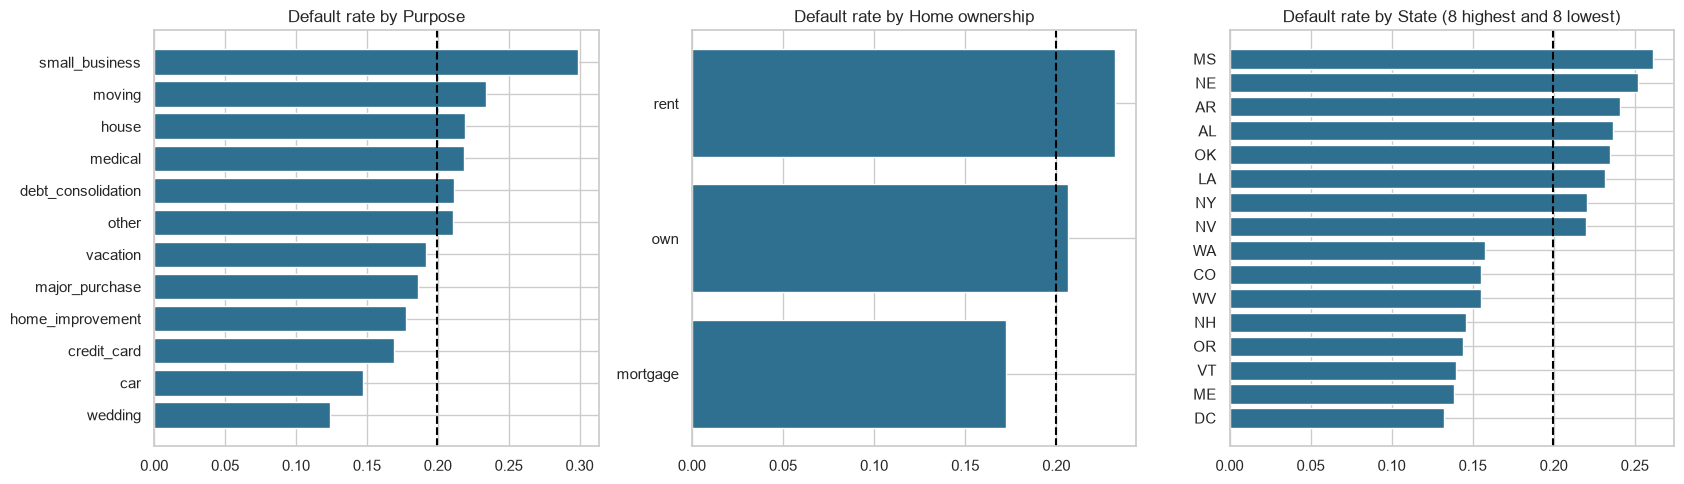

,loans,default_rate
Purpose,,
small_business,15575,0.299
moving,9520,0.234
house,7294,0.219
medical,15606,0.218
debt_consolidation,781206,0.212
other,78263,0.211
vacation,9083,0.192
major_purchase,29543,0.186
home_improvement,87684,0.178


In [8]:
def default_rate_by_category(column, min_loans=2000):
    table = df.groupby(column)["Default"].agg(loans="size", default_rate="mean")
    return table[table["loans"] >= min_loans].sort_values("default_rate", ascending=False)


purpose_rates = default_rate_by_category("Purpose")
home_rates = default_rate_by_category("HomeOwnership")
state_rates = default_rate_by_category("State")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
panels = [
    (purpose_rates, "Purpose"),
    (home_rates, "Home ownership"),
    (pd.concat([state_rates.head(8), state_rates.tail(8)]), "State (8 highest and 8 lowest)"),
]
for ax, (table, title) in zip(axes, panels):
    ax.barh(table.index.astype(str)[::-1], table["default_rate"][::-1], color="#2F6F8F")
    ax.axvline(overall_default_rate, color="black", linestyle="--")
    ax.set_title(f"Default rate by {title}")
save_fig("05_default_rate_categories")

purpose_rates.round(3)

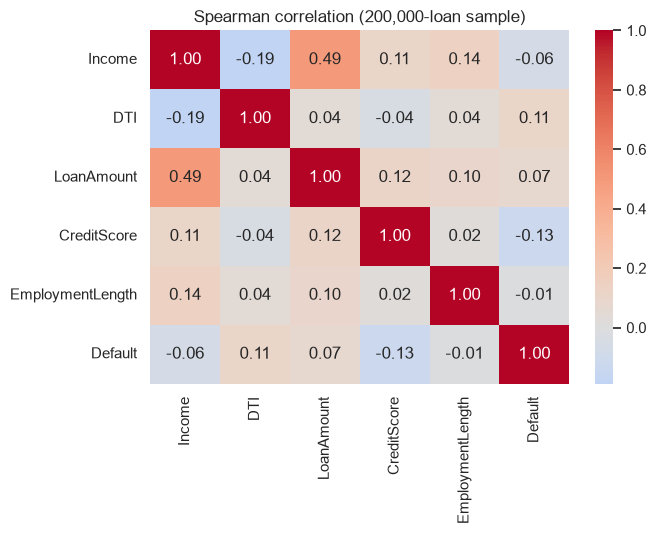

In [9]:
corr_sample = df.sample(200_000, random_state=1)[numeric_columns + ["Default"]]

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_sample.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation (200,000-loan sample)")
save_fig("06_correlation")

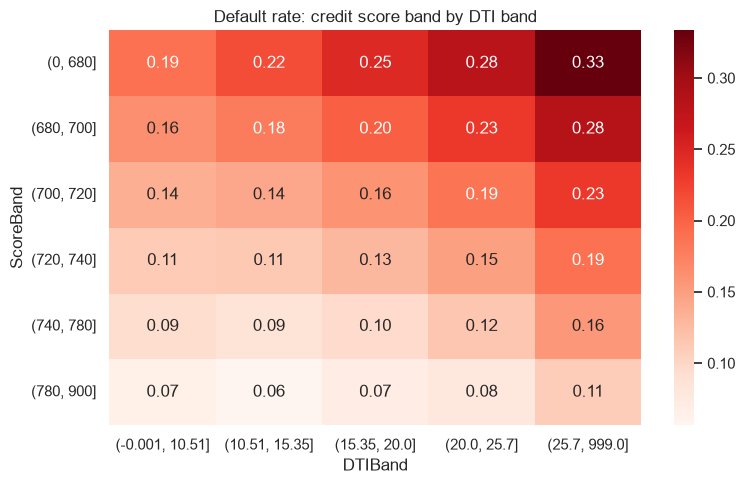

In [10]:
eda = df[["CreditScore", "DTI", "Default"]].copy()
eda["ScoreBand"] = pd.cut(eda["CreditScore"], [0, 680, 700, 720, 740, 780, 900])
eda["DTIBand"] = pd.qcut(eda["DTI"], 5, duplicates="drop")

counts = eda.pivot_table(index="ScoreBand", columns="DTIBand", values="Default", aggfunc="size", observed=True)
rates = eda.pivot_table(index="ScoreBand", columns="DTIBand", values="Default", aggfunc="mean", observed=True)
rates = rates.where(counts >= 500)            # hide cells with too few loans to trust

plt.figure(figsize=(8, 5))
sns.heatmap(rates, annot=True, fmt=".2f", cmap="Reds")
plt.title("Default rate: credit score band by DTI band")
save_fig("07_score_dti_heatmap")

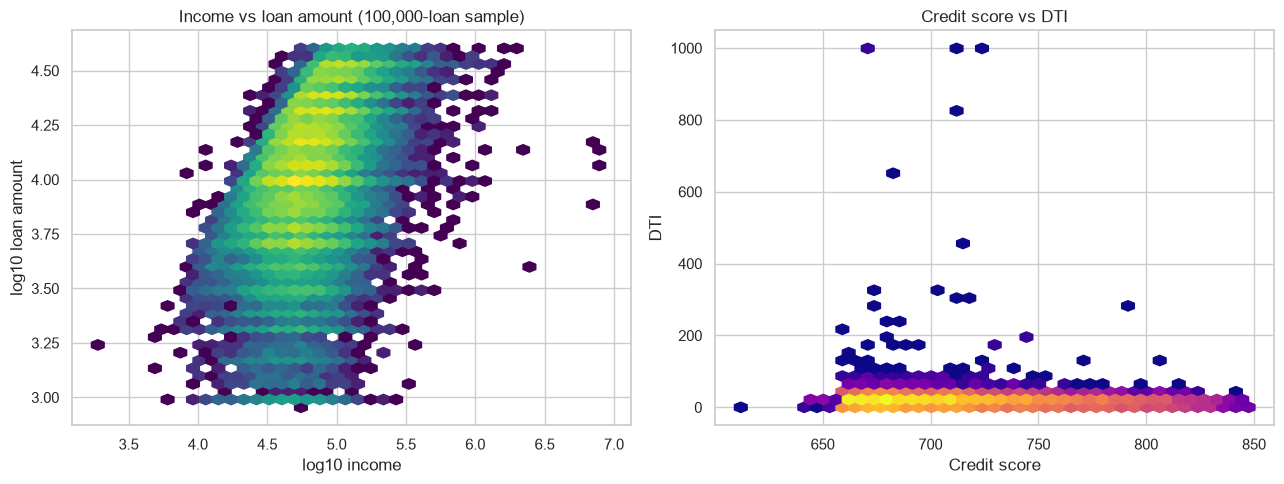

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

hb0 = axes[0].hexbin(np.log10(plot_sample["Income"]), np.log10(plot_sample["LoanAmount"]),
                     gridsize=40, cmap="viridis", bins="log", mincnt=1)
axes[0].set_xlabel("log10 income")
axes[0].set_ylabel("log10 loan amount")
axes[0].set_title("Income vs loan amount (100,000-loan sample)")

hb1 = axes[1].hexbin(plot_sample["CreditScore"], plot_sample["DTI"],
                     gridsize=40, cmap="plasma", bins="log", mincnt=1)
axes[1].set_xlabel("Credit score")
axes[1].set_ylabel("DTI")
axes[1].set_title("Credit score vs DTI")
save_fig("08_pairs")